In [149]:
files_to_check = [
    METRICS_DIR / "augmentation_validation_1to1.csv",
    METRICS_DIR / "augmentation_validation_extra_ratios.csv",
    METRICS_DIR / "augmentation_validation_all_ratios.csv",
    METRICS_DIR / "augmentation_strategy_summary.csv",
    METRICS_DIR / "augmentation_candidate_details.csv",
    METRICS_DIR / "synthetic_selection.json",
    FIGURES_DIR / "augmentation_ratio_ap_comparison.png"
]

for file in files_to_check:
    print(
        file.name,
        "→",
        file.exists()
    )

augmentation_validation_1to1.csv → True
augmentation_validation_extra_ratios.csv → True
augmentation_validation_all_ratios.csv → True
augmentation_strategy_summary.csv → True
augmentation_candidate_details.csv → True
synthetic_selection.json → True
augmentation_ratio_ap_comparison.png → True


## Conclusion du notebook

Ce notebook a permis de comparer quatre stratégies d'augmentation
des transactions frauduleuses : SMOTE, GAN, CGAN et Autoencoder.

L'évaluation a combiné :

- la fidélité statistique des données synthétiques ;
- leur diversité et leur proximité avec les fraudes réelles ;
- leur utilité prédictive sur une Validation exclusivement réelle ;
- l'effet de plusieurs ratios Fraude/Normal.

Les résultats montrent qu'un équilibrage complet 1:1 n'est pas
nécessairement optimal.

La stratégie retenue est SMOTE avec un ratio Fraude/Normal de 0.10.

Cette stratégie sera utilisée dans le notebook suivant pour entraîner
les cinq classifieurs avant leur évaluation finale sur le jeu de Test réel.

In [147]:
import json

selection = {
    "augmentation_method": BEST_METHOD,
    "target_fraud_normal_ratio": BEST_RATIO,
    "selection_dataset": "real_validation",
    "primary_metric": "average_precision",
    "secondary_metrics": [
        "f1",
        "recall",
        "precision"
    ],
    "test_used_for_selection": False
}

with open(
    METRICS_DIR / "synthetic_selection.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selection,
        f,
        indent=4,
        ensure_ascii=False
    )

strategy_summary.to_csv(
    METRICS_DIR / "augmentation_strategy_summary.csv",
    index=False
)

candidate_details.to_csv(
    METRICS_DIR / "augmentation_candidate_details.csv",
    index=False
)

print("Sélection sauvegardée.")
print("Méthode :", BEST_METHOD)
print("Ratio :", BEST_RATIO)

Sélection sauvegardée.
Méthode : SMOTE
Ratio : 0.1


In [146]:
BEST_METHOD = "SMOTE"
BEST_RATIO = 0.10

selected_strategy = strategy_summary[
    (strategy_summary["Augmentation"] == BEST_METHOD)
    &
    (strategy_summary["Ratio"] == BEST_RATIO)
]

display(
    selected_strategy.round(4)
)

,Augmentation,Ratio,Mean_AP,Std_AP,Mean_F1,Mean_Recall,Mean_Precision,Mean_ROC_AUC,Mean_Balanced_Accuracy,Delta_AP_vs_Baseline,Delta_F1_vs_Baseline,Delta_Recall_vs_Baseline,Delta_Precision_vs_Baseline
1,SMOTE,0.1,0.7721,0.0854,0.7767,0.7944,0.7896,0.9721,0.8969,0.1517,0.1697,0.2901,0.0063


## Étape 29 — Sélection finale de la stratégie d'augmentation

Après comparaison des quatre méthodes et des différents ratios,
la stratégie SMOTE avec un ratio Fraude/Normal de 0.10 est retenue.

Cette stratégie présente une Average Precision pratiquement
équivalente à la meilleure valeur observée, tout en offrant un
meilleur équilibre entre Precision, Recall et F1-score.

La sélection est réalisée exclusivement à partir du jeu de
Validation réel. Le jeu de Test n'a pas été utilisé pour cette décision.

In [145]:
candidate_strategies = pd.DataFrame(
    [
        ["Autoencoder", 0.25],
        ["SMOTE", 0.10],
        ["GAN", 0.25],
        ["CGAN", 0.50]
    ],
    columns=[
        "Augmentation",
        "Ratio"
    ]
)

candidate_details = (
    validation_all_ratios_df
    .merge(
        candidate_strategies,
        on=[
            "Augmentation",
            "Ratio"
        ],
        how="inner"
    )
    .sort_values(
        [
            "Augmentation",
            "Modèle"
        ]
    )
    .reset_index(drop=True)
)

display(
    candidate_details[
        [
            "Augmentation",
            "Ratio",
            "Modèle",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "AP"
        ]
    ].round(4)
)

,Augmentation,Ratio,Modèle,Precision,Recall,F1,ROC_AUC,AP
0,Autoencoder,0.25,LightGBM,0.9808,0.7183,0.8293,0.9664,0.8385
1,Autoencoder,0.25,Random Forest,1.0000,0.7183,0.8361,0.9600,0.8277
2,Autoencoder,0.25,Régression logistique,0.1644,0.8451,0.2752,0.9708,0.6699
3,Autoencoder,0.25,SVM linéaire,0.1960,0.8310,0.3172,0.9696,0.6792
4,Autoencoder,0.25,XGBoost,1.0000,0.7324,0.8455,0.9707,0.8465
5,CGAN,0.50,LightGBM,0.9649,0.7746,0.8594,0.9824,0.8452
6,CGAN,0.50,Random Forest,0.9194,0.8028,0.8571,0.9442,0.8081
7,CGAN,0.50,Régression logistique,0.5730,0.7183,0.6375,0.9668,0.6190
8,CGAN,0.50,SVM linéaire,0.7273,0.6761,0.7007,0.9635,0.6526
9,CGAN,0.50,XGBoost,0.9180,0.7887,0.8485,0.9702,0.8352


## Étape 28 — Analyse détaillée des meilleures stratégies

Les moyennes permettent d'identifier les stratégies les plus
prometteuses, mais elles peuvent masquer des différences importantes
entre les classifieurs.

Les meilleures stratégies sont donc examinées individuellement
sur les cinq modèles afin de vérifier leur régularité et d'éviter
une sélection fondée uniquement sur une moyenne globale.

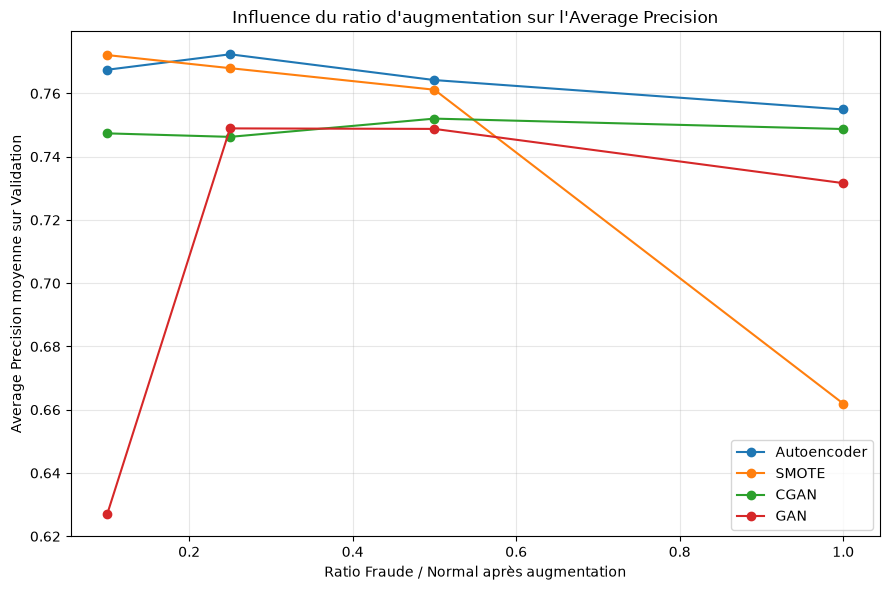

In [144]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

for method in strategy_summary[
    "Augmentation"
].unique():

    subset = (
        strategy_summary[
            strategy_summary[
                "Augmentation"
            ] == method
        ]
        .sort_values("Ratio")
    )

    ax.plot(
        subset["Ratio"],
        subset["Mean_AP"],
        marker="o",
        label=method
    )

ax.set_xlabel(
    "Ratio Fraude / Normal après augmentation"
)

ax.set_ylabel(
    "Average Precision moyenne sur Validation"
)

ax.set_title(
    "Influence du ratio d'augmentation sur l'Average Precision"
)

ax.legend()

ax.grid(
    alpha=0.3
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR /
    "augmentation_ratio_ap_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [143]:
display(
    strategy_summary[
        [
            "Augmentation",
            "Ratio",
            "Mean_AP",
            "Delta_AP_vs_Baseline",
            "Mean_F1",
            "Delta_F1_vs_Baseline",
            "Mean_Recall",
            "Delta_Recall_vs_Baseline",
            "Mean_Precision",
            "Delta_Precision_vs_Baseline"
        ]
    ].round(4)
)

,Augmentation,Ratio,Mean_AP,Delta_AP_vs_Baseline,Mean_F1,Delta_F1_vs_Baseline,Mean_Recall,Delta_Recall_vs_Baseline,Mean_Precision,Delta_Precision_vs_Baseline
0,Autoencoder,0.25,0.7724,0.1519,0.6207,0.0137,0.7690,0.2648,0.6682,-0.1151
1,SMOTE,0.10,0.7721,0.1517,0.7767,0.1697,0.7944,0.2901,0.7896,0.0063
2,SMOTE,0.25,0.7680,0.1476,0.6170,0.0100,0.8000,0.2958,0.6034,-0.1800
3,Autoencoder,0.10,0.7675,0.1471,0.7176,0.1106,0.7634,0.2592,0.7502,-0.0332
4,Autoencoder,0.50,0.7642,0.1438,0.5938,-0.0132,0.7803,0.2761,0.6411,-0.1423
5,SMOTE,0.50,0.7612,0.1407,0.5662,-0.0408,0.8169,0.3127,0.5576,-0.2257
6,Autoencoder,1.00,0.7549,0.1345,0.5619,-0.0451,0.7690,0.2648,0.6224,-0.1609
7,CGAN,0.50,0.7520,0.1316,0.7806,0.1737,0.7521,0.2479,0.8205,0.0372
8,GAN,0.25,0.7489,0.1285,0.8074,0.2004,0.7887,0.2845,0.8380,0.0546
9,GAN,0.50,0.7488,0.1284,0.7822,0.1753,0.7887,0.2845,0.7986,0.0152


In [142]:
strategy_summary[
    "Delta_AP_vs_Baseline"
] = (
    strategy_summary["Mean_AP"]
    -
    baseline_ap
)

strategy_summary[
    "Delta_F1_vs_Baseline"
] = (
    strategy_summary["Mean_F1"]
    -
    baseline_f1
)

strategy_summary[
    "Delta_Recall_vs_Baseline"
] = (
    strategy_summary["Mean_Recall"]
    -
    baseline_recall
)

strategy_summary[
    "Delta_Precision_vs_Baseline"
] = (
    strategy_summary["Mean_Precision"]
    -
    baseline_precision
)

In [141]:
baseline_ap = float(
    baseline_validation_df[
        "AP"
    ].mean()
)

baseline_f1 = float(
    baseline_validation_df[
        "F1"
    ].mean()
)

baseline_recall = float(
    baseline_validation_df[
        "Recall"
    ].mean()
)

baseline_precision = float(
    baseline_validation_df[
        "Precision"
    ].mean()
)

In [140]:
if "baseline_validation_df" not in globals():

    baseline_validation_df = pd.read_csv(
        METRICS_DIR /
        "baseline_validation_recomputed.csv"
    )

print(
    baseline_validation_df.shape
)

(5, 8)


In [139]:
top_strategies = (
    strategy_summary
    .head(10)
    .copy()
)

display(
    top_strategies.round(4)
)

,Augmentation,Ratio,Mean_AP,Std_AP,Mean_F1,Mean_Recall,Mean_Precision,Mean_ROC_AUC,Mean_Balanced_Accuracy
0,Autoencoder,0.25,0.7724,0.0896,0.6207,0.7690,0.6682,0.9675,0.8832
1,SMOTE,0.10,0.7721,0.0854,0.7767,0.7944,0.7896,0.9721,0.8969
2,SMOTE,0.25,0.7680,0.0919,0.6170,0.8000,0.6034,0.9718,0.8987
3,Autoencoder,0.10,0.7675,0.0786,0.7176,0.7634,0.7502,0.9641,0.8813
4,Autoencoder,0.50,0.7642,0.0940,0.5938,0.7803,0.6411,0.9662,0.8882
5,SMOTE,0.50,0.7612,0.0988,0.5662,0.8169,0.5576,0.9719,0.9060
6,Autoencoder,1.00,0.7549,0.0989,0.5619,0.7690,0.6224,0.9623,0.8817
7,CGAN,0.50,0.7520,0.1076,0.7806,0.7521,0.8205,0.9654,0.8759
8,GAN,0.25,0.7489,0.1030,0.8074,0.7887,0.8380,0.9646,0.8942
9,GAN,0.50,0.7488,0.1005,0.7822,0.7887,0.7986,0.9630,0.8941


In [138]:
strategy_summary = (
    strategy_summary
    .sort_values(
        [
            "Mean_AP",
            "Mean_F1",
            "Mean_Recall"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    strategy_summary.round(4)
)

,Augmentation,Ratio,Mean_AP,Std_AP,Mean_F1,Mean_Recall,Mean_Precision,Mean_ROC_AUC,Mean_Balanced_Accuracy
0,Autoencoder,0.25,0.7724,0.0896,0.6207,0.7690,0.6682,0.9675,0.8832
1,SMOTE,0.10,0.7721,0.0854,0.7767,0.7944,0.7896,0.9721,0.8969
2,SMOTE,0.25,0.7680,0.0919,0.6170,0.8000,0.6034,0.9718,0.8987
3,Autoencoder,0.10,0.7675,0.0786,0.7176,0.7634,0.7502,0.9641,0.8813
4,Autoencoder,0.50,0.7642,0.0940,0.5938,0.7803,0.6411,0.9662,0.8882
5,SMOTE,0.50,0.7612,0.0988,0.5662,0.8169,0.5576,0.9719,0.9060
6,Autoencoder,1.00,0.7549,0.0989,0.5619,0.7690,0.6224,0.9623,0.8817
7,CGAN,0.50,0.7520,0.1076,0.7806,0.7521,0.8205,0.9654,0.8759
8,GAN,0.25,0.7489,0.1030,0.8074,0.7887,0.8380,0.9646,0.8942
9,GAN,0.50,0.7488,0.1005,0.7822,0.7887,0.7986,0.9630,0.8941


In [137]:
strategy_summary = (
    validation_all_ratios_df
    .groupby(
        [
            "Augmentation",
            "Ratio"
        ]
    )
    .agg(

        Mean_AP=(
            "AP",
            "mean"
        ),

        Std_AP=(
            "AP",
            "std"
        ),

        Mean_F1=(
            "F1",
            "mean"
        ),

        Mean_Recall=(
            "Recall",
            "mean"
        ),

        Mean_Precision=(
            "Precision",
            "mean"
        ),

        Mean_ROC_AUC=(
            "ROC_AUC",
            "mean"
        ),

        Mean_Balanced_Accuracy=(
            "Balanced_Accuracy",
            "mean"
        )
    )
    .reset_index()
)

## Étape 24 — Comparaison des couples Méthode × Ratio

Les performances d'une méthode d'augmentation peuvent varier
selon la quantité de données synthétiques ajoutées.

L'analyse est donc réalisée conjointement sur la méthode
d'augmentation et le ratio Fraude/Normal.

Pour chaque couple Méthode × Ratio, les performances moyennes
obtenues avec les cinq classifieurs sont calculées sur la
Validation réelle.

L'Average Precision constitue le critère principal, tandis que
le F1-score, le Recall et la Precision sont utilisés comme
critères complémentaires.

In [136]:
validation_all_ratios_df.to_csv(
    METRICS_DIR /
    "augmentation_validation_all_ratios.csv",
    index=False
)

In [135]:
validation_all_ratios_df = (
    validation_all_ratios_df
    .sort_values(
        [
            "Augmentation",
            "Ratio",
            "Modèle"
        ]
    )
    .reset_index(drop=True)
)

print(
    "Nombre total d'expériences :",
    len(validation_all_ratios_df)
)

Nombre total d'expériences : 80


In [134]:
validation_all_ratios_df = pd.concat(
    [
        validation_extra_ratios_df,
        validation_1to1_complete
    ],
    ignore_index=True
)

In [133]:
validation_1to1_complete = (
    validation_1to1_df.copy()
)

validation_1to1_complete[
    "N_normal_train"
] = int(
    (y_train == 0).sum()
)

validation_1to1_complete[
    "N_fraud_train"
] = int(
    (y_train == 0).sum()
)

In [132]:
validation_extra_ratios_df.to_csv(
    METRICS_DIR /
    "augmentation_validation_extra_ratios.csv",
    index=False
)

print("Résultats sauvegardés.")

Résultats sauvegardés.


In [131]:
validation_extra_ratios_df = pd.DataFrame(
    ratio_validation_rows
)

print(
    "Nombre d'expériences :",
    len(validation_extra_ratios_df)
)

display(
    validation_extra_ratios_df.round(4)
)

Nombre d'expériences : 60


,Augmentation,Modèle,Ratio,N_normal_train,N_fraud_train,Temps_s,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,SMOTE,Régression logistique,0.10,198277,19828,0.4589,0.9982,0.9148,0.4836,0.8310,0.6114,0.9672,0.6682
1,SMOTE,SVM linéaire,0.10,198277,19828,1.2497,0.9990,0.9081,0.6667,0.8169,0.7342,0.9714,0.6921
2,SMOTE,Random Forest,0.10,198277,19828,25.2658,0.9995,0.8732,0.9464,0.7465,0.8346,0.9696,0.8553
3,SMOTE,XGBoost,0.10,198277,19828,1.6173,0.9995,0.8943,0.9180,0.7887,0.8485,0.9772,0.8194
4,SMOTE,LightGBM,0.10,198277,19828,1.0915,0.9996,0.8943,0.9333,0.7887,0.8550,0.9753,0.8255
5,SMOTE,Régression logistique,0.25,198277,49569,0.6848,0.9930,0.9122,0.1720,0.8310,0.2850,0.9667,0.6623
6,SMOTE,SVM linéaire,0.25,198277,49569,1.9257,0.9941,0.9127,0.1993,0.8310,0.3215,0.9708,0.6747
7,SMOTE,Random Forest,0.25,198277,49569,26.5205,0.9995,0.8732,0.9464,0.7465,0.8346,0.9698,0.8561
8,SMOTE,XGBoost,0.25,198277,49569,1.7127,0.9994,0.9013,0.8507,0.8028,0.8261,0.9738,0.8251
9,SMOTE,LightGBM,0.25,198277,49569,1.2215,0.9994,0.8942,0.8485,0.7887,0.8175,0.9779,0.8218


In [130]:
for method, synthetic_data in synthetic_sets.items():

    print("\n")
    print("=" * 60)
    print("MÉTHODE :", method)
    print("=" * 60)

    for ratio in RATIOS_TO_TEST:

        print(
            f"\nRatio cible Fraude/Normal = {ratio}"
        )

        X_aug, y_aug = build_augmented_train(
            X_train=X_train,
            y_train=y_train,
            synthetic_data=synthetic_data,
            target_ratio=ratio,
            random_state=SEED
        )

        n_normal = int(
            (y_aug == 0).sum()
        )

        n_fraud = int(
            (y_aug == 1).sum()
        )

        print(
            "Normales :", n_normal,
            "| Fraudes :", n_fraud
        )

        models = make_models()

        for model_name, model in models.items():

            print(
                "   →",
                model_name
            )

            start = time.perf_counter()

            model.fit(
                X_aug,
                y_aug
            )

            elapsed = (
                time.perf_counter()
                -
                start
            )

            metrics = evaluate_classifier(
                model,
                X_val,
                y_val
            )

            ratio_validation_rows.append({

                "Augmentation":
                    method,

                "Modèle":
                    model_name,

                "Ratio":
                    ratio,

                "N_normal_train":
                    n_normal,

                "N_fraud_train":
                    n_fraud,

                "Temps_s":
                    elapsed,

                **metrics
            })

        del X_aug
        del y_aug



MÉTHODE : SMOTE

Ratio cible Fraude/Normal = 0.1
Normales : 198277 | Fraudes : 19828
   → Régression logistique
   → SVM linéaire
   → Random Forest
   → XGBoost
   → LightGBM

Ratio cible Fraude/Normal = 0.25
Normales : 198277 | Fraudes : 49569
   → Régression logistique
   → SVM linéaire
   → Random Forest
   → XGBoost
   → LightGBM

Ratio cible Fraude/Normal = 0.5
Normales : 198277 | Fraudes : 99138
   → Régression logistique
   → SVM linéaire
   → Random Forest
   → XGBoost
   → LightGBM


MÉTHODE : GAN

Ratio cible Fraude/Normal = 0.1
Normales : 198277 | Fraudes : 19828
   → Régression logistique
   → SVM linéaire
   → Random Forest
   → XGBoost
   → LightGBM

Ratio cible Fraude/Normal = 0.25
Normales : 198277 | Fraudes : 49569
   → Régression logistique
   → SVM linéaire
   → Random Forest
   → XGBoost
   → LightGBM

Ratio cible Fraude/Normal = 0.5
Normales : 198277 | Fraudes : 99138
   → Régression logistique
   → SVM linéaire
   → Random Forest
   → XGBoost
   → LightGBM


MÉ

## Étape 21 — Évaluation des différents niveaux d'augmentation

Les quatre stratégies d'augmentation sont maintenant évaluées
avec plusieurs ratios Fraude/Normal.

L'objectif est de déterminer si un équilibrage complet 1:1 est
réellement nécessaire ou si une quantité plus modérée de données
synthétiques permet d'obtenir de meilleures performances sur des
transactions réelles.

Pour chaque couple Méthode × Ratio, les cinq classifieurs de la
baseline sont réentraînés avec exactement les mêmes paramètres.

La comparaison est réalisée exclusivement sur le jeu de
Validation réel.

In [128]:
RATIOS_TO_TEST = [
    0.10,
    0.25,
    0.50
]

ratio_validation_rows = []

print(
    "Ratios à tester :",
    RATIOS_TO_TEST
)


Ratios à tester : [0.1, 0.25, 0.5]


In [127]:
import time

SEED = 42

required_objects = [
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "synthetic_sets",
    "build_augmented_train",
    "make_models",
    "evaluate_classifier",
    "get_model_scores"
]

for name in required_objects:
    print(
        name,
        "→",
        name in globals()
    )

X_train → True
y_train → True
X_val → True
y_val → True
synthetic_sets → True
build_augmented_train → True
make_models → True
evaluate_classifier → True
get_model_scores → True


In [126]:
print(
    "build_augmented_train :",
    "build_augmented_train" in globals()
)

print(
    "make_models :",
    "make_models" in globals()
)

print(
    "evaluate_classifier :",
    "evaluate_classifier" in globals()
)

print(
    "get_model_scores :",
    "get_model_scores" in globals()
)

build_augmented_train : True
make_models : True
evaluate_classifier : True
get_model_scores : True


In [125]:
from pathlib import Path
import time
import numpy as np
import pandas as pd

# =========================
# 1. Chemins du projet
# =========================

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SYNTHETIC_DIR = PROJECT_ROOT / "results" / "synthetic"

SEED = 42


# =========================
# 2. Recharger Train + Validation
# =========================

X_train = pd.read_parquet(
    PROCESSED_DIR / "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR / "y_train.parquet"
).squeeze()

X_val = pd.read_parquet(
    PROCESSED_DIR / "X_val.parquet"
)

y_val = pd.read_parquet(
    PROCESSED_DIR / "y_val.parquet"
).squeeze()

print("Train :", X_train.shape)
print("Validation :", X_val.shape)


# =========================
# 3. Recharger les données synthétiques
# =========================

synthetic_paths = {
    "SMOTE":
        SYNTHETIC_DIR / "smote_fraud_synthetic.parquet",

    "GAN":
        SYNTHETIC_DIR / "gan_fraud_synthetic.parquet",

    "CGAN":
        SYNTHETIC_DIR / "cgan_fraud_synthetic.parquet",

    "Autoencoder":
        SYNTHETIC_DIR / "autoencoder_fraud_synthetic.parquet"
}

synthetic_sets = {}

for method, path in synthetic_paths.items():

    df = pd.read_parquet(path)

    # Retirer Class si elle existe
    if "Class" in df.columns:
        df = df.drop(columns=["Class"])

    synthetic_sets[method] = df

    print(
        method,
        "→",
        df.shape
    )

Train : (198608, 30)
Validation : (42559, 30)
SMOTE → (197946, 30)
GAN → (197946, 30)
CGAN → (197946, 30)
Autoencoder → (197946, 30)


In [124]:
RATIOS_TO_TEST = [
    0.10,
    0.25,
    0.50
]

ratio_validation_rows = []

## Étape 20 — Étude de sensibilité au ratio d'augmentation

L'expérience précédente a comparé les quatre stratégies
d'augmentation avec un ratio Fraude/Normal égal à 1.0.

Ce ratio correspond à un équilibrage complet du jeu
d'entraînement et constitue une augmentation très importante
de la classe frauduleuse.

Cependant, une quantité excessive de données synthétiques
peut modifier artificiellement la distribution d'apprentissage
et augmenter le nombre de faux positifs.

Afin de vérifier la stabilité des résultats, plusieurs niveaux
d'augmentation sont maintenant étudiés :

- 0.10
- 0.25
- 0.50
- 1.00

La sélection est toujours réalisée exclusivement sur le jeu
de Validation réel.

Le jeu de Test reste totalement exclu de cette procédure.

In [123]:
BEST_METHOD_1TO1 = (
    method_summary.iloc[0][
        "Augmentation"
    ]
)

print(
    "Méthode la mieux classée au ratio 1:1 :",
    BEST_METHOD_1TO1
)

Méthode la mieux classée au ratio 1:1 : Autoencoder


In [122]:
method_summary = (
    validation_1to1_df
    .groupby("Augmentation")
    .agg(
        Mean_AP=("AP", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_Precision=("Precision", "mean"),
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Mean_Balanced_Accuracy=(
            "Balanced_Accuracy",
            "mean"
        )
    )
    .reset_index()
)

method_summary = (
    method_summary
    .sort_values(
        [
            "Mean_AP",
            "Mean_F1",
            "Mean_Recall"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    method_summary.round(4)
)

,Augmentation,Mean_AP,Mean_F1,Mean_Recall,Mean_Precision,Mean_ROC_AUC,Mean_Balanced_Accuracy
0,Autoencoder,0.7549,0.5619,0.7690,0.6224,0.9623,0.8817
1,CGAN,0.7487,0.7722,0.7662,0.7967,0.9657,0.8829
2,GAN,0.7316,0.7379,0.7915,0.7391,0.9626,0.8954
3,SMOTE,0.6619,0.4731,0.8225,0.4392,0.9694,0.9061


In [121]:
from pathlib import Path
import pandas as pd

# Racine du projet
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

# Recharger les résultats déjà calculés à l'étape 17
validation_1to1_df = pd.read_csv(
    METRICS_DIR / "augmentation_validation_1to1.csv"
)

print(
    "Résultats 1:1 rechargés :",
    validation_1to1_df.shape
)

Résultats 1:1 rechargés : (20, 11)


In [120]:
method_summary = (
    method_summary
    .sort_values(
        [
            "Mean_AP",
            "Mean_F1",
            "Mean_Recall"
        ],
        ascending=False
    )
)

display(
    method_summary.round(4)
)

,Augmentation,Mean_AP,Mean_F1,Mean_Recall,Mean_Precision,Mean_ROC_AUC,Mean_Balanced_Accuracy
0,Autoencoder,0.7549,0.5619,0.7690,0.6224,0.9623,0.8817
1,CGAN,0.7487,0.7722,0.7662,0.7967,0.9657,0.8829
2,GAN,0.7316,0.7379,0.7915,0.7391,0.9626,0.8954
3,SMOTE,0.6619,0.4731,0.8225,0.4392,0.9694,0.9061


In [119]:
method_summary = (
    validation_1to1_df
    .groupby("Augmentation")
    .agg(

        Mean_AP=(
            "AP",
            "mean"
        ),

        Mean_F1=(
            "F1",
            "mean"
        ),

        Mean_Recall=(
            "Recall",
            "mean"
        ),

        Mean_Precision=(
            "Precision",
            "mean"
        ),

        Mean_ROC_AUC=(
            "ROC_AUC",
            "mean"
        ),

        Mean_Balanced_Accuracy=(
            "Balanced_Accuracy",
            "mean"
        )

    )
    .reset_index()
)

## Étape 18 — Résumé global des méthodes d'augmentation

Les résultats précédents contiennent cinq modèles pour chacune
des quatre stratégies d'augmentation.

Afin d'obtenir une vision globale, les performances moyennes
des cinq classifieurs sont calculées pour chaque méthode.

L'AP moyenne constitue le critère principal de comparaison,
car elle est particulièrement informative dans un problème
fortement déséquilibré.

Le F1 moyen et le Recall moyen sont utilisés comme critères
complémentaires.

Cette étape sélectionne une stratégie d'augmentation,
et non le modèle final du système.

In [118]:
validation_1to1_df.to_csv(
    METRICS_DIR /
    "augmentation_validation_1to1.csv",
    index=False
)

In [117]:
validation_1to1_df = pd.DataFrame(
    validation_rows
)

display(
    validation_1to1_df.round(4)
)

,Augmentation,Modèle,Ratio,Temps_s,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,SMOTE,Régression logistique,1.0,2.0373,0.9729,0.9302,0.0521,0.8873,0.0984,0.9679,0.6496
1,SMOTE,SVM linéaire,1.0,3.1397,0.9774,0.9254,0.0611,0.8732,0.1143,0.9699,0.6657
2,SMOTE,Random Forest,1.0,48.2248,0.9995,0.8732,0.9298,0.7465,0.8281,0.9756,0.8480
3,SMOTE,XGBoost,1.0,3.0551,0.9991,0.8941,0.7000,0.7887,0.7417,0.9809,0.8223
4,SMOTE,LightGBM,1.0,1.7871,0.9980,0.9076,0.4531,0.8169,0.5829,0.9525,0.3241
5,GAN,Régression logistique,1.0,0.9052,0.9975,0.9003,0.3851,0.8028,0.5205,0.9555,0.6256
6,GAN,SVM linéaire,1.0,1.1864,0.9982,0.9007,0.4790,0.8028,0.6000,0.9630,0.6338
7,GAN,Random Forest,1.0,68.3623,0.9996,0.9014,0.9344,0.8028,0.8636,0.9583,0.8126
8,GAN,XGBoost,1.0,2.6604,0.9996,0.8873,0.9649,0.7746,0.8594,0.9667,0.8241
9,GAN,LightGBM,1.0,1.8783,0.9995,0.8873,0.9322,0.7746,0.8462,0.9695,0.7622


In [116]:
validation_rows = []

for method, synthetic_data in synthetic_sets.items():

    print(
        "\n============================"
    )

    print(
        "Augmentation :",
        method
    )

    X_aug, y_aug = (
        build_augmented_train(
            X_train,
            y_train,
            synthetic_data,
            target_ratio=1.0,
            random_state=SEED
        )
    )

    print(
        "Train augmenté :",
        X_aug.shape
    )

    print(
        y_aug.value_counts().to_dict()
    )

    models = make_models()

    for model_name, model in models.items():

        print(
            "  →",
            model_name
        )

        start = (
            time.perf_counter()
        )

        model.fit(
            X_aug,
            y_aug
        )

        training_time = (
            time.perf_counter()
            -
            start
        )

        metrics = evaluate_classifier(
            model,
            X_val,
            y_val
        )

        validation_rows.append({

            "Augmentation":
                method,

            "Modèle":
                model_name,

            "Ratio":
                1.0,

            "Temps_s":
                training_time,

            **metrics
        })

    del X_aug
    del y_aug


Augmentation : SMOTE
Train augmenté : (396554, 30)
{0: 198277, 1: 198277}
  → Régression logistique
  → SVM linéaire
  → Random Forest
  → XGBoost
  → LightGBM

Augmentation : GAN
Train augmenté : (396554, 30)
{0: 198277, 1: 198277}
  → Régression logistique
  → SVM linéaire
  → Random Forest
  → XGBoost
  → LightGBM

Augmentation : CGAN
Train augmenté : (396554, 30)
{0: 198277, 1: 198277}
  → Régression logistique
  → SVM linéaire
  → Random Forest
  → XGBoost
  → LightGBM

Augmentation : Autoencoder
Train augmenté : (396554, 30)
{0: 198277, 1: 198277}
  → Régression logistique
  → SVM linéaire
  → Random Forest
  → XGBoost
  → LightGBM


In [ ]:
baseline_val_df.to_csv(
    METRICS_DIR /
    "baseline_validation_recomputed.csv",
    index=False
)

In [115]:
baseline_rows = []

baseline_models = make_models()

for model_name, model in baseline_models.items():

    print(
        "Baseline :",
        model_name
    )

    model.fit(
        X_train,
        y_train
    )

    metrics = evaluate_classifier(
        model,
        X_val,
        y_val
    )

    baseline_rows.append({

        "Modèle":
            model_name,

        **metrics
    })

baseline_val_df = pd.DataFrame(
    baseline_rows
)

display(
    baseline_val_df.round(4)
)

Baseline : Régression logistique
Baseline : SVM linéaire
Baseline : Random Forest
Baseline : XGBoost
Baseline : LightGBM


,Modèle,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,Régression logistique,0.9988,0.6971,0.8235,0.3944,0.5333,0.9673,0.6873
1,SVM linéaire,0.9990,0.7253,0.8649,0.4507,0.5926,0.9717,0.7160
2,Random Forest,0.9996,0.8944,0.9825,0.7887,0.8750,0.9336,0.8204
3,XGBoost,0.9995,0.8380,1.0000,0.6761,0.8067,0.9734,0.8251
4,LightGBM,0.9976,0.6051,0.2459,0.2113,0.2273,0.6050,0.0533


In [114]:
def build_augmented_train(
    X_train,
    y_train,
    synthetic_data,
    target_ratio=1.0,
    random_state=42
):

    n_normal = int(
        (y_train == 0).sum()
    )

    n_real_fraud = int(
        (y_train == 1).sum()
    )

    target_fraud = int(
        round(
            target_ratio
            *
            n_normal
        )
    )

    n_synthetic_needed = (
        target_fraud
        -
        n_real_fraud
    )

    if n_synthetic_needed < 0:

        raise ValueError(
            "Le ratio demandé est inférieur "
            "au nombre actuel de fraudes."
        )

    if n_synthetic_needed > len(
        synthetic_data
    ):

        raise ValueError(
            "Pas assez de données synthétiques "
            "pour atteindre ce ratio."
        )

    synthetic_sample = (
        synthetic_data.sample(
            n=n_synthetic_needed,
            random_state=random_state
        )
        .reset_index(drop=True)
    )

    y_synthetic = pd.Series(
        np.ones(
            n_synthetic_needed,
            dtype=np.int8
        ),
        name=y_train.name
    )

    X_augmented = pd.concat(
        [
            X_train.reset_index(
                drop=True
            ),

            synthetic_sample
        ],
        ignore_index=True
    )

    y_augmented = pd.concat(
        [
            y_train.reset_index(
                drop=True
            ),

            y_synthetic
        ],
        ignore_index=True
    )

    return (
        X_augmented,
        y_augmented
    )

In [113]:
def evaluate_classifier(
    model,
    X_eval,
    y_eval
):

    y_pred = model.predict(
        X_eval
    )

    y_score = get_model_scores(
        model,
        X_eval
    )

    return {

        "Accuracy":
            accuracy_score(
                y_eval,
                y_pred
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_eval,
                y_pred
            ),

        "Precision":
            precision_score(
                y_eval,
                y_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_eval,
                y_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_eval,
                y_pred,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_eval,
                y_score
            ),

        "AP":
            average_precision_score(
                y_eval,
                y_score
            )
    }

In [112]:
def get_model_scores(
    model,
    X
):

    if hasattr(
        model,
        "predict_proba"
    ):

        return model.predict_proba(
            X
        )[:, 1]

    if hasattr(
        model,
        "decision_function"
    ):

        return model.decision_function(
            X
        )

    return model.predict(
        X
    )

In [111]:
def make_models():

    return {

        "Régression logistique":

            LogisticRegression(
                max_iter=2000,
                class_weight=None,
                random_state=42
            ),

        "SVM linéaire":

            LinearSVC(
                C=1.0,
                class_weight=None,
                max_iter=5000,
                random_state=42
            ),

        "Random Forest":

            RandomForestClassifier(
                n_estimators=200,
                class_weight=None,
                random_state=42,
                n_jobs=-1
            ),

        "XGBoost":

            XGBClassifier(
                n_estimators=200,
                learning_rate=0.1,
                max_depth=6,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            ),

        "LightGBM":

            LGBMClassifier(
                n_estimators=200,
                learning_rate=0.1,
                class_weight=None,
                random_state=42,
                n_jobs=-1,
                verbosity=-1
            )
    }

## Étape 11 — Évaluation de l'utilité prédictive

La qualité statistique d'un jeu synthétique ne garantit pas qu'il
améliore la classification.

Chaque stratégie d'augmentation est donc utilisée pour construire
un nouveau jeu d'entraînement.

Les cinq classifieurs de la baseline sont ensuite réentraînés avec
les mêmes configurations.

Les performances sont mesurées exclusivement sur le jeu de
Validation réel.

Cette expérience permet de déterminer si les données synthétiques
apportent réellement une information utile pour détecter de
nouvelles fraudes réelles.

In [110]:
detection_df.to_csv(
    METRICS_DIR /
    "real_vs_synthetic_detection.csv",
    index=False
)

In [109]:
detection_rows = []

for method, synthetic_data in synthetic_sets.items():

    mean_auc, std_auc = (
        real_vs_synthetic_auc(
            X_real_fraud,
            synthetic_data
        )
    )

    detection_rows.append({

        "Méthode":
            method,

        "Detection_AUC":
            mean_auc,

        "Detection_STD":
            std_auc
    })

detection_df = pd.DataFrame(
    detection_rows
)

display(
    detection_df.round(4)
)

,Méthode,Detection_AUC,Detection_STD
0,SMOTE,0.4144,0.0178
1,GAN,0.8824,0.0248
2,CGAN,0.9921,0.0019
3,Autoencoder,0.5415,0.0297


In [108]:
def real_vs_synthetic_auc(
    real_data,
    synthetic_data,
    random_state=42
):

    n = min(
        len(real_data),
        len(synthetic_data)
    )

    synthetic_sample = (
        synthetic_data.sample(
            n=n,
            random_state=random_state
        )
        .reset_index(drop=True)
    )

    real_sample = (
        real_data.sample(
            n=n,
            random_state=random_state
        )
        .reset_index(drop=True)
    )

    X_detection = pd.concat(
        [
            real_sample,
            synthetic_sample
        ],
        ignore_index=True
    )

    # 1 = réel
    # 0 = synthétique
    y_detection = np.concatenate(
        [
            np.ones(n),
            np.zeros(n)
        ]
    )

    detector = make_pipeline(

        StandardScaler(),

        LogisticRegression(
            max_iter=2000,
            random_state=random_state
        )
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )

    auc_scores = cross_val_score(
        detector,
        X_detection,
        y_detection,
        cv=cv,
        scoring="roc_auc"
    )

    return (
        auc_scores.mean(),
        auc_scores.std()
    )

## Étape 10 — Détectabilité réel / synthétique

Un classifieur auxiliaire est utilisé pour distinguer les fraudes
réelles des fraudes synthétiques.

Une AUC proche de 0.5 indique que la distinction est difficile.

Une AUC nettement supérieure à 0.5 indique que les données
synthétiques présentent des caractéristiques permettant de les
distinguer des données réelles.

Cette métrique reste un diagnostic complémentaire et ne constitue
pas à elle seule un critère de sélection.

In [107]:
diversity_df = quality_df[
    [
        "Méthode",
        "Diversité_réelle",
        "Diversité_synthétique",
        "Ratio_diversité",
        "Écart_ratio_diversité",
        "Médiane_réel_réel",
        "Médiane_synth_réel"
    ]
].copy()

diversity_df = diversity_df.rename(
    columns={
        "Diversité_réelle": "Diversité réelle",
        "Diversité_synthétique": "Diversité synthétique",
        "Ratio_diversité": "Ratio diversité",
        "Écart_ratio_diversité": "Écart à 1 ↓",
        "Médiane_réel_réel": "Distance réel→réel",
        "Médiane_synth_réel": "Distance synth→réel"
    }
)

styled_diversity = (
    diversity_df
    .style
    .hide(axis="index")
    .format({
        "Diversité réelle": "{:.4f}",
        "Diversité synthétique": "{:.4f}",
        "Ratio diversité": "{:.4f}",
        "Écart à 1 ↓": "{:.4f}",
        "Distance réel→réel": "{:.4f}",
        "Distance synth→réel": "{:.4f}"
    })
    .set_caption(
        "Comparaison de la diversité et de la proximité avec les fraudes réelles"
    )
)

display(styled_diversity)

Méthode,Diversité réelle,Diversité synthétique,Ratio diversité,Écart à 1 ↓,Distance réel→réel,Distance synth→réel
SMOTE,0.9269,0.8941,0.9646,0.0354,0.2325,0.0622
GAN,0.9269,0.9278,1.0010,0.0010,0.2325,0.3220
CGAN,0.9269,0.8301,0.8956,0.1044,0.2325,0.3573
Autoencoder,0.9269,0.8387,0.9049,0.0951,0.2325,0.2048


In [105]:
quality_df["Écart_ratio_diversité"] = abs(
    quality_df["Ratio_diversité"] - 1
)

In [99]:
quality_df["Écart_ratio_diversité"] = abs(
    quality_df["Ratio_diversité"] - 1
)

In [106]:
quality_df["Écart_ratio_diversité"] = abs(
    quality_df["Ratio_diversité"] - 1
)

print("Colonne créée avec succès.")

Colonne créée avec succès.


In [84]:
quality_stat_df = quality_df[
    [
        "Méthode",
        "NaN",
        "Inf",
        "Doublons",
        "Copies_exactes",
        "Hors_minmax_pct",
        "KS_moyen",
        "KS_max",
        "Wasserstein_moyen",
        "Spearman_MAE"
    ]
].copy()

quality_stat_df = quality_stat_df.rename(
    columns={
        "Copies_exactes": "Copies exactes",
        "Hors_minmax_pct": "Hors min/max (%)",
        "KS_moyen": "KS moyen ↓",
        "KS_max": "KS max ↓",
        "Wasserstein_moyen": "Wasserstein moyen ↓",
        "Spearman_MAE": "Erreur Spearman ↓"
    }
)

styled_quality = (
    quality_stat_df
    .style
    .hide(axis="index")
    .format({
        "Hors min/max (%)": "{:.3f}",
        "KS moyen ↓": "{:.4f}",
        "KS max ↓": "{:.4f}",
        "Wasserstein moyen ↓": "{:.5f}",
        "Erreur Spearman ↓": "{:.4f}"
    })
    .set_caption(
        "Comparaison de la fidélité statistique des données synthétiques"
    )
)

display(styled_quality)

Méthode,NaN,Inf,Doublons,Copies exactes,Hors min/max (%),KS moyen ↓,KS max ↓,Wasserstein moyen ↓,Erreur Spearman ↓
SMOTE,0,0,0,0,0.000,0.0367,0.0575,0.00473,0.0300
GAN,0,0,0,0,1.853,0.1525,0.2996,0.02105,0.2202
CGAN,0,0,0,0,2.550,0.2082,0.5413,0.03509,0.2744
Autoencoder,0,0,11,0,0.078,0.1381,0.3117,0.01657,0.1807


In [85]:
quality_df.to_csv(
    METRICS_DIR /
    "synthetic_quality_comparison.csv",
    index=False
)

In [86]:
quality_results = []

for method, synthetic_data in synthetic_sets.items():

    print(
        f"Évaluation : {method}"
    )

    result = evaluate_synthetic_quality(
        X_real_fraud,
        synthetic_data,
        method
    )

    quality_results.append(
        result
    )

quality_df = pd.DataFrame(
    quality_results
)

display(
    quality_df.round(6)
)

Évaluation : SMOTE
Évaluation : GAN
Évaluation : CGAN
Évaluation : Autoencoder


,Méthode,NaN,Inf,Doublons,Copies_exactes,Hors_minmax_pct,KS_moyen,KS_max,Wasserstein_moyen,Spearman_MAE,Diversité_réelle,Diversité_synthétique,Ratio_diversité,Médiane_réel_réel,Médiane_synth_réel
0,SMOTE,0,0,0,0,0.000000,0.036675,0.057478,0.004726,0.029994,0.926864,0.894091,0.964641,0.232469,0.062181
1,GAN,0,0,0,0,1.853165,0.152545,0.299603,0.021054,0.220210,0.926864,0.927821,1.001033,0.232469,0.321997
2,CGAN,0,0,0,0,2.549601,0.208202,0.541336,0.035088,0.274379,0.926864,0.830053,0.895550,0.232469,0.357314
3,Autoencoder,0,0,11,0,0.077631,0.138116,0.311695,0.016568,0.180677,0.926864,0.838715,0.904896,0.232469,0.204842


In [87]:
def evaluate_synthetic_quality(
    real_data,
    synthetic_data,
    method_name,
    random_state=42
):

    real = real_data.reset_index(drop=True)
    synthetic = synthetic_data.reset_index(drop=True)

    # --------------------------------
    # Intégrité
    # --------------------------------

    nan_count = int(
        synthetic.isna().sum().sum()
    )

    inf_count = int(
        np.isinf(
            synthetic.to_numpy()
        ).sum()
    )

    duplicate_count = int(
        synthetic.duplicated().sum()
    )

    # Copies exactes
    real_index = pd.MultiIndex.from_frame(
        real
    )

    synthetic_index = pd.MultiIndex.from_frame(
        synthetic
    )

    exact_copies = int(
        synthetic_index.isin(
            real_index
        ).sum()
    )

    # --------------------------------
    # Valeurs hors domaine réel
    # --------------------------------

    real_min = real.min()
    real_max = real.max()

    outside = (
        synthetic.lt(real_min)
        |
        synthetic.gt(real_max)
    )

    outside_count = int(
        outside.sum().sum()
    )

    outside_pct = (
        100
        * outside_count
        / synthetic.size
    )

    # --------------------------------
    # KS + Wasserstein
    # --------------------------------

    ks_values = []
    wasserstein_values = []

    for feature in real.columns:

        real_values = real[
            feature
        ].to_numpy()

        synth_values = synthetic[
            feature
        ].to_numpy()

        ks_stat, _ = ks_2samp(
            real_values,
            synth_values
        )

        wass = wasserstein_distance(
            real_values,
            synth_values
        )

        ks_values.append(
            ks_stat
        )

        wasserstein_values.append(
            wass
        )

    # --------------------------------
    # Spearman
    # --------------------------------

    real_corr = real.corr(
        method="spearman"
    )

    synthetic_corr = synthetic.corr(
        method="spearman"
    )

    corr_diff = np.abs(
        real_corr.to_numpy()
        -
        synthetic_corr.to_numpy()
    )

    # Partie supérieure uniquement,
    # sans diagonale.
    upper_triangle = np.triu_indices_from(
        corr_diff,
        k=1
    )

    spearman_values = corr_diff[
        upper_triangle
    ]

    spearman_mae = np.nanmean(
        spearman_values
    )

    # --------------------------------
    # Diversité
    # --------------------------------

    n_diversity = min(
        len(real),
        len(synthetic)
    )

    synthetic_div_sample = (
        synthetic.sample(
            n=n_diversity,
            random_state=random_state
        )
    )

    real_diversity = pdist(
        real.to_numpy()
    ).mean()

    synthetic_diversity = pdist(
        synthetic_div_sample.to_numpy()
    ).mean()

    diversity_ratio = (
        synthetic_diversity
        /
        real_diversity
    )

    # --------------------------------
    # Proximité / mémorisation
    # --------------------------------

    nn = NearestNeighbors(
        n_neighbors=2,
        metric="euclidean"
    )

    nn.fit(
        real.to_numpy()
    )

    real_distances, _ = nn.kneighbors(
        real.to_numpy()
    )

    median_real_real = np.median(
        real_distances[:, 1]
    )

    synthetic_nn_sample = (
        synthetic.sample(
            n=min(
                5000,
                len(synthetic)
            ),
            random_state=random_state
        )
    )

    synthetic_distances, _ = nn.kneighbors(
        synthetic_nn_sample.to_numpy(),
        n_neighbors=1
    )

    median_synthetic_real = np.median(
        synthetic_distances[:, 0]
    )

    return {
        "Méthode": method_name,

        "NaN": nan_count,
        "Inf": inf_count,
        "Doublons": duplicate_count,
        "Copies_exactes": exact_copies,

        "Hors_minmax_pct": outside_pct,

        "KS_moyen": np.mean(
            ks_values
        ),

        "KS_max": np.max(
            ks_values
        ),

        "Wasserstein_moyen": np.mean(
            wasserstein_values
        ),

        "Spearman_MAE": spearman_mae,

        "Diversité_réelle": real_diversity,

        "Diversité_synthétique":
            synthetic_diversity,

        "Ratio_diversité":
            diversity_ratio,

        "Médiane_réel_réel":
            median_real_real,

        "Médiane_synth_réel":
            median_synthetic_real
    }

## Étape 8 — Fonction commune d’évaluation de la qualité synthétique

Après avoir chargé et harmonisé les quatre ensembles synthétiques
(SMOTE, GAN, CGAN et Autoencoder), cette étape consiste à définir
une fonction unique permettant de les évaluer selon exactement les
mêmes critères.

L’objectif est d’assurer une comparaison équitable, reproductible et
scientifiquement cohérente entre les différentes méthodes de génération.

La fonction calcule notamment :

- l’intégrité des données : valeurs manquantes, valeurs infinies,
  doublons et copies exactes ;
- la fidélité statistique : test de Kolmogorov-Smirnov (KS) et distance
  de Wasserstein ;
- la conservation des relations entre variables à l’aide des
  corrélations de Spearman ;
- la diversité globale des données synthétiques ;
- la proximité entre les transactions synthétiques et les fraudes
  réelles afin de détecter une éventuelle mémorisation.

Toutes les méthodes sont comparées aux mêmes 331 fraudes réelles du
jeu d’entraînement et avec la même procédure de calcul.

À ce stade, aucune méthode n’est encore sélectionnée.
Cette étape constitue uniquement une évaluation de la qualité
statistique et structurelle des données synthétiques.

In [88]:
synthetic_sets = {}

for method, path in synthetic_paths.items():

    df = pd.read_parquet(path)

    # Supprimer Class si elle existe
    if "Class" in df.columns:

        print(
            f"{method} : colonne Class détectée"
        )

        print(
            df["Class"].value_counts()
        )

        df = df.drop(
            columns=["Class"]
        )

    # Vérifier que les 30 colonnes sont maintenant identiques à X_train
    if list(df.columns) != list(X_train.columns):

        raise ValueError(
            f"Colonnes incompatibles pour {method}"
        )

    synthetic_sets[method] = df

    print(
        method,
        ":",
        df.shape
    )

SMOTE : colonne Class détectée
Class
1    197946
Name: count, dtype: int64
SMOTE : (197946, 30)
GAN : colonne Class détectée
Class
1    197946
Name: count, dtype: int64
GAN : (197946, 30)
CGAN : colonne Class détectée
Class
1    197946
Name: count, dtype: int64
CGAN : (197946, 30)
Autoencoder : (197946, 30)


In [89]:
synthetic_sets = {}

for method, path in synthetic_paths.items():

    df = pd.read_parquet(path)

    # Si une colonne Class existe, on la retire
    if "Class" in df.columns:

        print(
            f"{method} : colonne Class détectée"
        )

        print(
            df["Class"].value_counts()
        )

        df = df.drop(
            columns=["Class"]
        )

    # Vérification finale
    if list(df.columns) != list(X_train.columns):

        raise ValueError(
            f"Colonnes incompatibles pour {method}"
        )

    synthetic_sets[method] = df

    print(
        method,
        ":",
        df.shape
    )

SMOTE : colonne Class détectée
Class
1    197946
Name: count, dtype: int64
SMOTE : (197946, 30)
GAN : colonne Class détectée
Class
1    197946
Name: count, dtype: int64
GAN : (197946, 30)
CGAN : colonne Class détectée
Class
1    197946
Name: count, dtype: int64
CGAN : (197946, 30)
Autoencoder : (197946, 30)


In [90]:
smote_df = pd.read_parquet(
    synthetic_paths["SMOTE"]
)

print(smote_df["Class"].value_counts())

Class
1    197946
Name: count, dtype: int64


In [91]:
smote_df = pd.read_parquet(
    synthetic_paths["SMOTE"]
)

print("X_train :", X_train.shape)
print("SMOTE   :", smote_df.shape)

print("\nColonnes X_train :")
print(X_train.columns.tolist())

print("\nColonnes SMOTE :")
print(smote_df.columns.tolist())

X_train : (198608, 30)
SMOTE   : (197946, 31)

Colonnes X_train :
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Colonnes SMOTE :
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [92]:
for method, path in synthetic_paths.items():
    print(
        method,
        "→",
        path.exists(),
        "→",
        path.name
    )

SMOTE → True → smote_fraud_synthetic.parquet
GAN → True → gan_fraud_synthetic.parquet
CGAN → True → cgan_fraud_synthetic.parquet
Autoencoder → True → autoencoder_fraud_synthetic.parquet


In [93]:
synthetic_paths = {

    "SMOTE":
        SYNTHETIC_DIR /
        "smote_fraud_synthetic.parquet",

    "GAN":
        SYNTHETIC_DIR /
        "gan_fraud_synthetic.parquet",

    "CGAN":
        SYNTHETIC_DIR /
        "cgan_fraud_synthetic.parquet",

    "Autoencoder":
        SYNTHETIC_DIR /
        "autoencoder_fraud_synthetic.parquet"
}

In [94]:
fraud_mask = (
    y_train.to_numpy() == 1
)

X_real_fraud = (
    X_train.loc[fraud_mask]
    .reset_index(drop=True)
)

print(
    "Fraudes réelles du Train :",
    X_real_fraud.shape
)

Fraudes réelles du Train : (331, 30)


In [95]:
X_train = pd.read_parquet(
    PROCESSED_DIR / "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR / "y_train.parquet"
).squeeze()

X_val = pd.read_parquet(
    PROCESSED_DIR / "X_val.parquet"
)

y_val = pd.read_parquet(
    PROCESSED_DIR / "y_val.parquet"
).squeeze()

print("Train :", X_train.shape)
print("Validation :", X_val.shape)

print("\nTrain :")
print(y_train.value_counts())

print("\nValidation :")
print(y_val.value_counts())

Train : (198608, 30)
Validation : (42559, 30)

Train :
Class
0    198277
1       331
Name: count, dtype: int64

Validation :
Class
0    42488
1       71
Name: count, dtype: int64


In [96]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SYNTHETIC_DIR = PROJECT_ROOT / "results" / "synthetic"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    METRICS_DIR,
    FIGURES_DIR,
    MODELS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Projet :", PROJECT_ROOT)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [97]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import pdist
from scipy.stats import ks_2samp, wasserstein_distance

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

SEED = 42

print("Imports OK")

Imports OK


# 08 — Comparaison et sélection des méthodes d'augmentation

## Objectif

Comparer de manière homogène les quatre stratégies d'augmentation :

- SMOTE
- Vanilla GAN
- CGAN
- Autoencoder

L'évaluation repose sur deux dimensions complémentaires :

1. qualité statistique des données synthétiques ;
2. utilité prédictive sur les données réelles de Validation.

Aucune donnée de Test n'est utilisée pour sélectionner une méthode.

La méthode d'augmentation finale sera choisie uniquement à partir
des résultats obtenus sur la Validation réelle.